# Introduction to Data Science 2026

# Week 6: Recap

## Exercise 1 | Linear regression with feature selection

Download the [TED Talks](https://www.kaggle.com/rounakbanik/ted-talks) dataset from Kaggle. Your task is to predict both the ratings and the number of views of a given TED talk. You should focus only on the <span style="font-weight: bold">ted_main</span> table.

1. Download the data, extract the following ratings from column <span style="font-weight: bold">ratings</span>: <span style="font-weight: bold">Funny</span>, <span style="font-weight: bold">Confusing</span>, <span style="font-weight: bold">Inspiring</span>. Store these values into respective columns so that they are easier to access. Next, extract the tags from column <span style="font-weight: bold">tags</span>. Count the number of occurrences of each tag and select the top-100 most common tags. Create a binary variable for each of these and include them in your data table, so that you can directly see whether a given tag (among the top-100 tags) is used in a given TED talk or not. The dataset you compose should have dimension (2550, 104), and comprise of the 'views' column, the three columns with counts of "Funny", "Confusing and "Inspiring" ratings, and 100 columns which one-hot encode the top-100 most common tag columns.


In [3]:
# Use this cell for your code
import ast
from collections import Counter
import numpy as np
import pandas as pd

ted = pd.read_csv('ted_main.csv')

rating_lists = ted['ratings'].apply(ast.literal_eval)
tag_lists = ted['tags'].apply(ast.literal_eval)

rating_names = ['Funny', 'Confusing', 'Inspiring']
rating_counts = pd.DataFrame(
    [{item['name']: item['count'] for item in ratings} for ratings in rating_lists],
    index=ted.index
)[rating_names].fillna(0).astype(int)


tag_frequencies = Counter(tag for tags in tag_lists for tag in tags)
top_100_tags = [tag for tag, count in tag_frequencies.most_common(100)]

tag_features = pd.DataFrame({
    tag: tag_lists.apply(lambda tags: int(tag in tags))
    for tag in top_100_tags
}, index=ted.index)


data = pd.concat([ted[['views']], rating_counts, tag_features], axis=1)
print('Data shape:', data.shape)
assert data.shape == (2550, 104)
display(data.head())

Data shape: (2550, 104)


,views,Funny,Confusing,Inspiring,technology,science,global issues,culture,TEDx,design,...,food,religion,peace,ecology,family,demo,poetry,illness,universe,energy
0,47227110,19645,242,24924,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1,3200520,544,62,413,1,1,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1636292,964,27,230,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1697550,59,32,1070,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,12005869,1390,72,2893,0,0,1,0,0,0,...,0,0,0,0,0,1,0,0,0,0


2. Construct a linear regression model to predict the number of views based on the data in the <span style="font-weight: bold">ted_main</span> table, including the binary variables for the top-100 tags that you just created.

In [4]:
# Use this cell for your code
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score


X = data[top_100_tags]
train_idx, test_idx = train_test_split(
    data.index, test_size=0.2, random_state=42
)
X_train, X_test = X.loc[train_idx], X.loc[test_idx]


y_train = data.loc[train_idx, 'views']
y_test = data.loc[test_idx, 'views']
views_model = LinearRegression().fit(X_train, y_train)
views_pred = views_model.predict(X_test)

linear_results = {
    'views': {
        'R2': r2_score(y_test, views_pred),
        'MAE': mean_absolute_error(y_test, views_pred)
    }
}
print('Views:')
print(f"Test R²: {linear_results['views']['R2']:.3f}")
print(f"Test MAE: {linear_results['views']['MAE']:,.0f} views")

Views:
Test R²: 0.164
Test MAE: 1,049,577 views


3. Do the same for the <span style="font-weight: bold">Funny</span>, <span style="font-weight: bold">Confusing</span>, and <span style="font-weight: bold">Inspiring</span> ratings.

In [5]:
# Use this cell for your code

linear_models = {'views': views_model}

for rating in rating_names:
    y_train = data.loc[train_idx, rating]
    y_test = data.loc[test_idx, rating]
    model = LinearRegression().fit(X_train, y_train)
    prediction = model.predict(X_test)

    linear_models[rating] = model
    linear_results[rating] = {
        'R2': r2_score(y_test, prediction),
        'MAE': mean_absolute_error(y_test, prediction)
    }

print('Ordinary linear regression (test set):')
display(pd.DataFrame(linear_results).T.round(3))

Ordinary linear regression (test set):


,R2,MAE
views,0.164,1049577.422
Funny,0.209,189.916
Confusing,0.190,15.770
Inspiring,0.077,488.756


4. You will probably notice that most of the tags are not useful in predicting the views and the ratings. You should use some kind of variable selection to prune the set of tags that are included in the model. You can use for example classical p-values or more modern [LASSO](https://en.wikipedia.org/wiki/Lasso_(statistics)) techniques. Which tags are the best predictors of each of the response variables?

In [6]:
# Use this cell for your code
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV


targets = ['views'] + rating_names
lasso_models = {}
selected_tags = {}
lasso_results = {}

for target in targets:
    model = make_pipeline(
        StandardScaler(),
        LassoCV(cv=5, random_state=42, max_iter=30000)
    )
    model.fit(X_train, data.loc[train_idx, target])
    prediction = model.predict(X_test)


    coefficients = pd.Series(
        model.named_steps['lassocv'].coef_, index=top_100_tags
    )
    selected = coefficients[coefficients.abs() > 1e-7]

    lasso_models[target] = model
    selected_tags[target] = selected
    lasso_results[target] = {
        'R2': r2_score(data.loc[test_idx, target], prediction),
        'MAE': mean_absolute_error(data.loc[test_idx, target], prediction),
        'Selected tags': len(selected)
    }

    print(f'\n{target} ({len(selected)} selected tags)')
    print('Strongest positive predictors:')
    display(selected.nlargest(5).round(3).rename('standardized coefficient').to_frame())
    print('Strongest negative predictors:')
    display(selected.nsmallest(5).round(3).rename('standardized coefficient').to_frame())


views (51 selected tags)
Strongest positive predictors:


,standardized coefficient
psychology,284128.438
work,198477.803
culture,177163.719
motivation,145837.717
demo,130088.093


Strongest negative predictors:


,standardized coefficient
art,-102256.583
global issues,-98315.878
design,-70313.389
politics,-61754.225
economics,-56253.634



Funny (46 selected tags)
Strongest positive predictors:


...

,standardized coefficient
innovation,-1.679
Africa,-1.428
animals,-1.196
TEDx,-1.051
music,-1.023



Inspiring (34 selected tags)
Strongest positive predictors:


,standardized coefficient
psychology,135.452
mental health,123.300
work,110.410
education,109.493
business,84.028


Strongest negative predictors:


,standardized coefficient
economics,-69.454
neuroscience,-58.253
art,-43.394
science,-39.143
technology,-36.751


5. Produce summaries of your results. Could you recommend good tags – or tags to avoid! – for speakers targeting plenty of views and/or certain ratings?

Test-set performance (MAE is measured in views or rating votes):


,Linear R²,LASSO R²,Linear MAE,LASSO MAE,Tags selected
views,0.164,0.163,1049577.422,1010964.832,51.0
Funny,0.209,0.257,189.916,163.551,46.0
Confusing,0.190,0.184,15.770,15.325,65.0
Inspiring,0.077,0.107,488.756,451.493,34.0


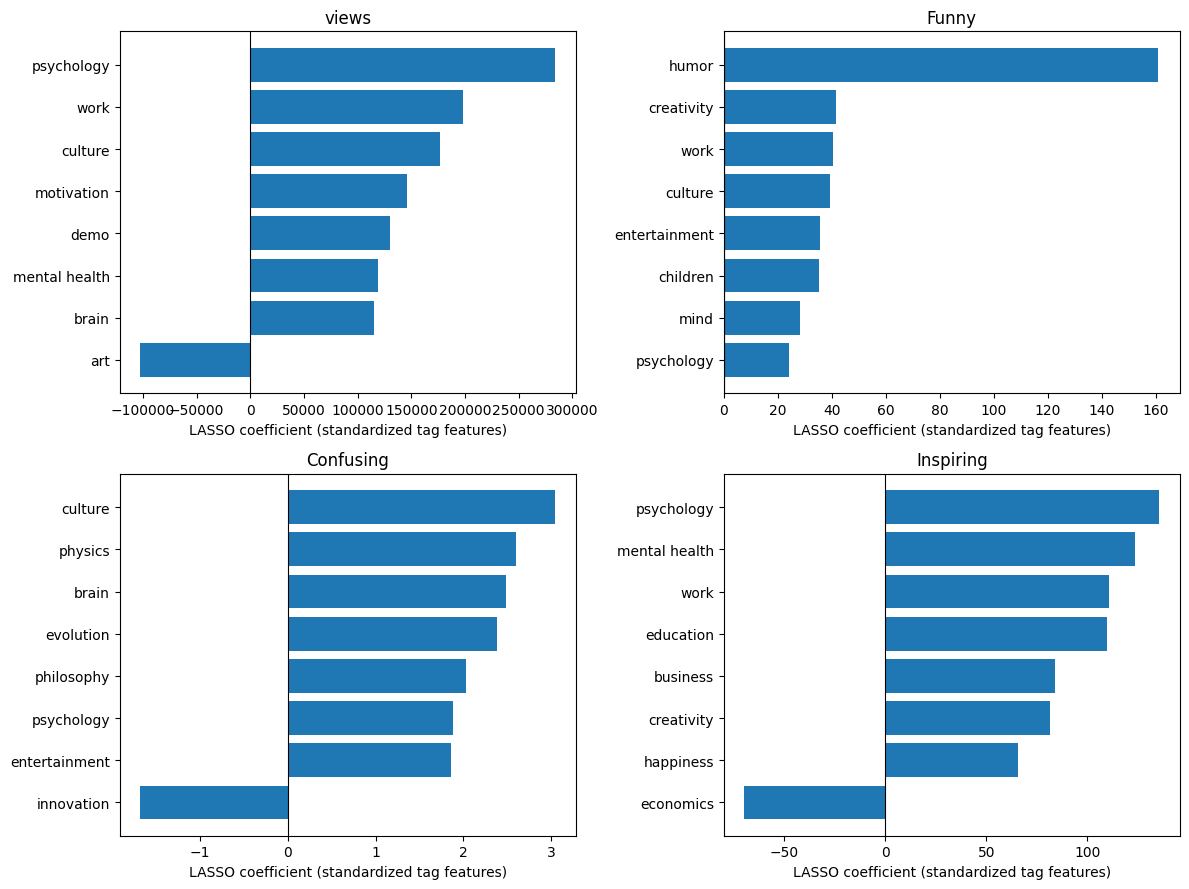

In [7]:
import matplotlib.pyplot as plt

# compare test-set results before/after feature selection
summary = pd.DataFrame({
    target: {
        'Linear R²': linear_results[target]['R2'],
        'LASSO R²': lasso_results[target]['R2'],
        'Linear MAE': linear_results[target]['MAE'],
        'LASSO MAE': lasso_results[target]['MAE'],
        'Tags selected': lasso_results[target]['Selected tags']
    }
    for target in targets
}).T
print('Test-set performance (MAE is measured in views or rating votes):')
display(summary.round(3))

# 8 strongest nonzero tag coefficients for each target.
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, target in zip(axes.flat, targets):
    coeff = selected_tags[target]
    strongest = coeff.loc[coeff.abs().nlargest(8).index].sort_values()
    ax.barh(strongest.index, strongest.values)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(target)
    ax.set_xlabel('LASSO coefficient (standardized tag features)')
plt.tight_layout()
plt.show()

answers: 

Based on the LASSO results, some tags are more useful than others for predicting views and ratings.

For views, tags such as psychology, work, culture, and motivation have positive coefficients, while art, global issues, and design have negative coefficients.

For the Funny rating, humor is the strongest positive predictor. For Confusing, tags such as physics, brain, and evolution are positively associated with higher counts. For Inspiring, psychology, mental health, work, and education are among the strongest positive predictors.

However, the R² scores are relatively low, indicating that tags alone cannot explain most of the variation in views and ratings. These results show correlations rather than causal relationships, so using a particular tag does not necessarily increase views or ratings.

**Remember to submit your code on the MOOC platform. You can return this Jupyter notebook (.ipynb) or .py, .R, etc depending on your programming preferences.**

## Exercise 2 | Symbol classification (part 2)

Note that it is strongly recommended to use Python in this exercise. However, if you can find a suitable AutoML implementation for your favorite language (e.g [here](http://h2o-release.s3.amazonaws.com/h2o/master/3888/docs-website/h2o-docs/automl.html) seems to be one for R) then you are free to use that language as well.

Use the preprocessed data from week 3 (you can also produce them using the example solutions of week 3).

1. This time train a *random forest classifier* on the data. A random forest is a collection of *decision trees*, which makes it an *ensemble* of classifiers. Each tree uses a random subset of the features to make its prediction. Without tuning any parameters, how is the accuracy?

In [1]:
# Use this cell for your code
!tar -xjf HASYv2.tar.bz2

In [2]:
# from week3: exercise 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

labels = pd.read_csv("hasy-data-labels.csv")
subset = labels[labels["symbol_id"].between(70, 79)]

X = np.array([
    np.asarray(Image.open(path).convert("L")).ravel() / 255
    for path in subset["path"]
])

y = subset["symbol_id"].to_numpy()

print(X.shape, y.shape)


# w6 ex2: random forest with default parameters
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
print("Test accuracy:", rf.score(X_test, y_test))

(1020, 1024) (1020,)
Test accuracy: 0.8088235294117647


2. The amount of trees to use as a part of the random forest is an example of a hyperparameter, because it is a parameter that is set prior to the learning process. In contrast, a parameter is a value in the model that is learned from the data. Train 20 classifiers, with varying amounts of decision trees starting from 10 up until 200, and plot the test accuracy as a function of the amount of classifiers. Does the accuracy keep increasing? Is more better?

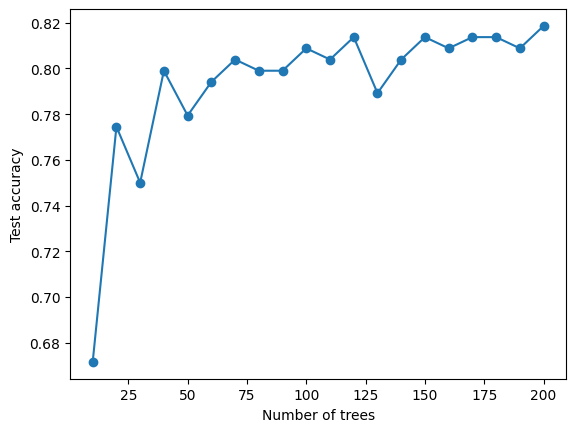

In [3]:
# Use this cell for your code
trees = range(10, 201, 10)
accuracies = []

for n in trees:
    rf = RandomForestClassifier(n_estimators=n, random_state=42)
    rf.fit(X_train, y_train)
    accuracies.append(rf.score(X_test, y_test))

plt.plot(trees, accuracies, marker="o")
plt.xlabel("Number of trees")
plt.ylabel("Test accuracy")
plt.show()

3. If we had picked the amount of decision trees by taking the value with the best test accuracy from the last plot, we would have *overfit* our hyperparameters to the test data. Can you see why it is a mistake to tune hyperparameters of your model by using the test data?

answer: Increasing the number of trees does not necessarily improve accuracy. 
Accuracy may fluctuate or stabilize after a certain point, while computational cost continues to increase.


4. Reshuffle and resplit the data so that it is divided in 3 parts: training (80%), validation (10%) and test (10%). Repeatedly train a model of your choosing (e.g random forest) on the training data, and evaluate it’s performance on the validation set, while tuning the hyperparameters so that the accuracy on the validation set increases. Then, finally evaluate the performance of your model on the test data. What can you say in terms of the generalization of your model?

In [4]:
# Use this cell for your code
X_train2, X_temp, y_train2, y_temp = train_test_split(
    X, y, test_size=0.2, random_state=123, stratify=y
)

X_val, X_test2, y_val, y_test2 = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=123, stratify=y_temp
)

best_accuracy = -1

for n in [10, 50, 100, 150, 200]:
    model = RandomForestClassifier(n_estimators=n, random_state=42)
    model.fit(X_train2, y_train2)

    val_accuracy = model.score(X_val, y_val)
    print(n, val_accuracy)

    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        best_model = model
        best_n = n

print("Best number of trees:", best_n)
print("Validation accuracy:", best_accuracy)
print("Test accuracy:", best_model.score(X_test2, y_test2))

10 0.7941176470588235
50 0.8627450980392157
100 0.8823529411764706
150 0.8627450980392157
200 0.8725490196078431
Best number of trees: 100
Validation accuracy: 0.8823529411764706
Test accuracy: 0.9019607843137255


**Remember to submit your code on the MOOC platform. You can return this Jupyter notebook (.ipynb) or .py, .R, etc depending on your programming preferences.**

## Exercise 3 | TPOT

The process of picking a suitable model, evaluating its performance and tuning the hyperparameters is very time consuming. A new idea in machine learning is the concept of automating this by using an optimization algorithm to find the best model in the space of models and their hyperparameters. Have a look at [TPOT](https://github.com/EpistasisLab/tpot), an automated ML solution that finds a good model and a good set of hyperparameters automatically. Try it on this data, it should outperform simple models like the ones we tried easily. Note that running the algorithm might take a while, depending on the strength of your computer. 

*Note*: In case it is running for too long, try checking if the parameters you are using when calling TPOT are reasonable, i.e. try reducing number of ‘generations’ or ‘population_size’. TPOT uses cross-validation internally, so we don’t need our own validation set.

In [1]:
%pip install tpot
%pip show tpot scikit-learn
%pip install --upgrade "scikit-learn==1.6.1" "tpot==1.1.0"


[notice] A new release of pip is available: 24.1.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Name: TPOT
Version: 1.1.0
Summary: Tree-based Pipeline Optimization Tool
Home-page: https://github.com/EpistasisLab/tpot
Author: Pedro Ribeiro
Author-email: 
License: GNU/LGPLv3
Location: /opt/conda/lib/python3.11/site-packages
Requires: configspace, dask, dask-expr, dask-jobqueue, dill, distributed, func-timeout, joblib, lightgbm, matplotlib, networkx, numpy, optuna, pandas, scikit-learn, scipy, seaborn, stopit, tqdm, traitlets, update-checker, xgboost
Required-by: 
---
Name: scikit-learn
Version: 1.6.1
Summary: A set of python modules for machine learning and data mining
Home-page: https://scikit-learn.org
Author: 
Author-email: 
License: BSD 3-Clause License

 Copyright (c) 2007-2024 The scikit-learn developers.
 All rights reserved.

 Redistribution and use in source and binary forms, with or without
 modi

In [11]:
from tpot import TPOTClassifier
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

#split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# TPOT classifier
tpot = TPOTClassifier(
    generations=1,
    population_size=5,
    search_space="linear-light",
    scorers=["accuracy"],
    cv=2,
    n_jobs=1,
    random_state=42,
    verbose=2
)

tpot.fit(X_train, y_train)

# random forest comparison
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

# evaluate TPOT
y_pred = tpot.predict(X_test)
y_pred = tpot.label_encoder_.inverse_transform(y_pred)

print("TPOT accuracy:", accuracy_score(y_test, y_pred))
print("Random Forest accuracy:", rf.score(X_test, y_test))
print("Best pipeline:", tpot.fitted_pipeline_)


/opt/conda/lib/python3.11/site-packages/tpot/tpot_estimator/estimator.py:458: UserWarning: Both generations and max_time_mins are set. TPOT will terminate when the first condition is met.
  warnings.warn("Both generations and max_time_mins are set. TPOT will terminate when the first condition is met.")
/opt/conda/lib/python3.11/site-packages/distributed/node.py:195: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 44081 instead
  warnings.warn(
/opt/conda/lib/python3.11/site-packages/tpot/tpot_estimator/estimator.py:537: UserWarning: Labels are not encoded as ints from 0 to N. For compatibility with some classifiers such as sklearn, TPOT has encoded y with the sklearn LabelEncoder. When using pipelines outside the main TPOT estimator class, you can encode the labels with est.label_encoder_
  warnings.warn("Labels are not encoded as ints from 0 to N. For compatibility with some classifiers such as sklearn, TPOT has enc

TPOT accuracy: 0.8480392156862745
Random Forest accuracy: 0.8333333333333334
Best pipeline: Pipeline(steps=[('minmaxscaler', MinMaxScaler()),
                ('variancethreshold',
                 VarianceThreshold(threshold=0.0378168026136)),
                ('featureunion-1',
                 FeatureUnion(transformer_list=[('skiptransformer',
                                                 SkipTransformer()),
                                                ('passthrough',
                                                 Passthrough())])),
                ('featureunion-2',
                 FeatureUnion(transformer_list=[('skiptransformer',
                                                 SkipTransformer()),
                                                ('passthrough',
                                                 Passthrough())])),
                ('logisticregression',
                 LogisticRegression(C=482.3236183104937,
                                    class_weight='ba

**Remember to submit your code on the MOOC platform. You can return this Jupyter notebook (.ipynb) or .py, .R, etc depending on your programming preferences.**